# Horizon for Data Governance: Governed Data, Governed AI
**SI Partner Workshop | 50 minutes | follow along live**

Governance is what lets you put AI in front of real client data without it leaking. In this session you build, step by step, the same pattern you can reuse on a client engagement:

1. Set up personas and least-privilege roles (RBAC)
2. Monitor data quality with Data Metric Functions
3. Classify sensitive data with AI and tag it once
4. Let that single tag drive masking, row filtering, and propagation to copies
5. See who touched what (audit)
6. Prove the **same policies protect Cortex Analyst** and unstructured text (AI_REDACT)

| Min | Section | Why it matters to you as a partner |
|---|---|---|
| 0-8 | 0. Setup | One script gives every client project the same four personas |
| 8-12 | 1. RBAC | Least privilege, shown by a failing query |
| 12-16 | 2. Data quality | Reusable "DQ starter kit" you can package |
| 16-23 | 3. AI classification | Find PII automatically instead of hand-mapping columns |
| 23-33 | 4. Protect: mask, filter, propagate | The core Horizon story, tag once and protect everywhere |
| 33-36 | 5. Audit | Evidence for compliance conversations |
| 36-44 | 6. Governed AI (semantic view) | No separate "AI policies" are needed |
| 44-47 | 7. AI_REDACT | Covers free text that classification cannot |
| 47-50 | 8. Ask governance in plain English, wrap-up | Next steps for your practice |
| (optional) | 8b. Intent-Driven Governance demo | Presenter only, a guided way to productise sections 3-4 |

Cells marked **(optional)** are skipped when time is short.

**The five Horizon pillars this lab touches:**

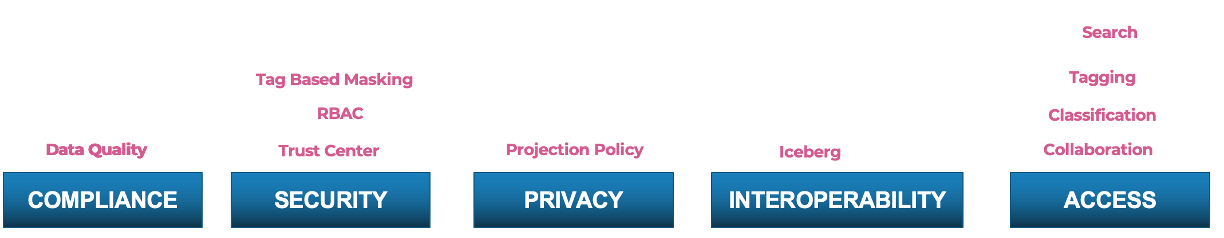

## Before you start

* You need **ACCOUNTADMIN** in a Snowflake account (a trial account is fine) with **Cortex enabled** for your region.
* Pick any running warehouse for this notebook. Setup creates its own `HRZN_WH` that the lab roles use.
* Run cells **top to bottom, one at a time**. Each cell says which role it runs as, and every SQL cell sets its own role with `USE ROLE`.
* **Secondary roles are switched off.** Every SQL cell starts with `USE SECONDARY ROLES NONE;`. Without it, a user whose default is `ALL` silently adds ACCOUNTADMIN's privileges to every persona, so the "expected error" cells would succeed. Keep that line if you copy cells elsewhere.
* A few cells are meant to **fail** ("Expected error"). That is the lesson, so don't fix them.
* **Heads up:** setup runs two `ALTER ACCOUNT` statements for Cortex (cross-region and model allowlist). Don't run it in a shared or production account without checking with the account owner.
* Everything is removed by the teardown cell at the very end.

**Further reading:** [Snowflake Horizon](https://docs.snowflake.com/en/user-guide/snowflake-horizon) | [USE SECONDARY ROLES](https://docs.snowflake.com/en/sql-reference/sql/use-secondary-roles) | [Authorization through primary and secondary roles](https://docs.snowflake.com/en/user-guide/security-access-control-overview)

---
# 0. Setup (about 8 min, run along with the presenter)

**What this does:** creates four personas that mirror a real governance team, a warehouse, the `HRZN_DB` database, and loads about 1k customers and their orders from a public sample bucket.

| Role | Persona | What they do in this lab |
|---|---|---|
| `HRZN_DATA_ENGINEER` | Builds pipelines | Owns the tables, defines data quality checks |
| `HRZN_DATA_GOVERNOR` | Data steward / CDO office | Classifies data, owns tags and policies |
| `HRZN_DATA_USER` | Analyst / business user | Consumes data, sees only what policy allows |
| `HRZN_IT_ADMIN` | Security / audit | Reads access history |

Where each persona fits in the Horizon story (the pink labels are the features you will touch):

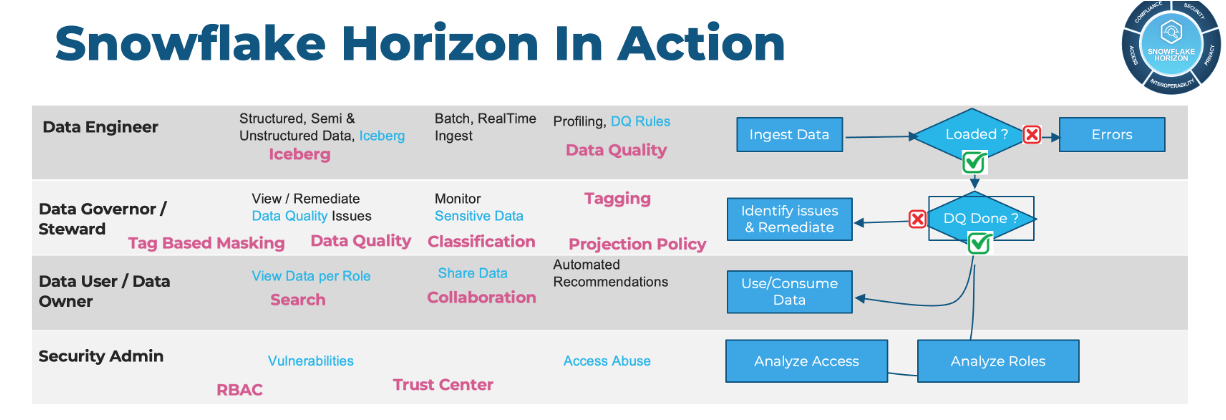

**Why it matters:** these four roles are a ready-made starting point for client engagements. Splitting "who builds", "who protects", and "who consumes" is what makes governance enforceable.

**0.1 Roles and warehouse** | run as `SECURITYADMIN` / `SYSADMIN`

In [ ]:
%%sql -r s0_roles
USE SECONDARY ROLES NONE;
USE ROLE SECURITYADMIN;
CREATE OR REPLACE ROLE HRZN_DATA_ENGINEER;
CREATE OR REPLACE ROLE HRZN_DATA_GOVERNOR;
CREATE OR REPLACE ROLE HRZN_DATA_USER;
CREATE OR REPLACE ROLE HRZN_IT_ADMIN;

GRANT ROLE HRZN_DATA_ENGINEER TO ROLE SYSADMIN;
GRANT ROLE HRZN_DATA_GOVERNOR TO ROLE SYSADMIN;
GRANT ROLE HRZN_DATA_USER TO ROLE SYSADMIN;
GRANT ROLE HRZN_IT_ADMIN TO ROLE SYSADMIN;

SET MY_USER_ID = CURRENT_USER();
GRANT ROLE HRZN_DATA_ENGINEER TO USER identifier($MY_USER_ID);
GRANT ROLE HRZN_DATA_GOVERNOR TO USER identifier($MY_USER_ID);
GRANT ROLE HRZN_DATA_USER TO USER identifier($MY_USER_ID);
GRANT ROLE HRZN_IT_ADMIN TO USER identifier($MY_USER_ID);

USE ROLE SYSADMIN;
CREATE OR REPLACE WAREHOUSE HRZN_WH WITH WAREHOUSE_SIZE = 'X-SMALL' AUTO_SUSPEND = 60;
GRANT USAGE ON WAREHOUSE HRZN_WH TO ROLE HRZN_DATA_ENGINEER;
GRANT USAGE ON WAREHOUSE HRZN_WH TO ROLE HRZN_DATA_GOVERNOR;
GRANT USAGE ON WAREHOUSE HRZN_WH TO ROLE HRZN_DATA_USER;
GRANT USAGE ON WAREHOUSE HRZN_WH TO ROLE HRZN_IT_ADMIN;

SELECT 'roles and warehouse ready' AS status;

**0.2 Database, schemas and baseline grants** | run as `HRZN_DATA_ENGINEER` / `HRZN_DATA_GOVERNOR` / `SECURITYADMIN`

In [ ]:
%%sql -r s0_database
USE SECONDARY ROLES NONE;
USE ROLE SECURITYADMIN;
GRANT CREATE DATABASE ON ACCOUNT TO ROLE HRZN_DATA_ENGINEER;

USE ROLE HRZN_DATA_ENGINEER;
USE WAREHOUSE HRZN_WH;
CREATE OR REPLACE DATABASE HRZN_DB;
CREATE OR REPLACE SCHEMA HRZN_DB.HRZN_SCH;

GRANT USAGE ON DATABASE HRZN_DB TO ROLE HRZN_DATA_GOVERNOR;
GRANT USAGE ON SCHEMA HRZN_DB.HRZN_SCH TO ROLE HRZN_DATA_GOVERNOR;
GRANT CREATE SCHEMA ON DATABASE HRZN_DB TO ROLE HRZN_DATA_GOVERNOR;

GRANT USAGE ON DATABASE HRZN_DB TO ROLE HRZN_IT_ADMIN;
GRANT USAGE ON SCHEMA HRZN_DB.HRZN_SCH TO ROLE HRZN_IT_ADMIN;
GRANT CREATE SCHEMA ON DATABASE HRZN_DB TO ROLE HRZN_IT_ADMIN;

GRANT USAGE ON DATABASE HRZN_DB TO ROLE HRZN_DATA_USER;
GRANT USAGE ON SCHEMA HRZN_DB.HRZN_SCH TO ROLE HRZN_DATA_USER;

-- Governor owns the governance objects: classifiers, tags/policies, and the role-to-state map
USE ROLE HRZN_DATA_GOVERNOR;
CREATE OR REPLACE SCHEMA HRZN_DB.CLASSIFIERS COMMENT = 'Schema containing Classifiers';
CREATE OR REPLACE SCHEMA HRZN_DB.TAG_SCHEMA COMMENT = 'Schema containing Tags';
CREATE OR REPLACE SCHEMA HRZN_DB.SEC_POLICIES_SCHEMA COMMENT = 'Schema containing Security Policies';

CREATE OR REPLACE TABLE HRZN_DB.TAG_SCHEMA.ROW_POLICY_MAP (role STRING, state_visibility STRING);
-- Data users may only see Massachusetts customers
INSERT INTO HRZN_DB.TAG_SCHEMA.ROW_POLICY_MAP VALUES ('HRZN_DATA_USER', 'MA');

USE ROLE SECURITYADMIN;
GRANT USAGE ON ALL SCHEMAS IN DATABASE HRZN_DB TO ROLE HRZN_DATA_GOVERNOR;
GRANT USAGE ON ALL SCHEMAS IN DATABASE HRZN_DB TO ROLE HRZN_DATA_USER;
GRANT USAGE ON ALL SCHEMAS IN DATABASE HRZN_DB TO ROLE HRZN_IT_ADMIN;

GRANT SELECT, INSERT, UPDATE, DELETE ON FUTURE TABLES IN SCHEMA HRZN_DB.HRZN_SCH TO ROLE HRZN_DATA_GOVERNOR;
GRANT SELECT, INSERT, UPDATE, DELETE ON FUTURE TABLES IN DATABASE HRZN_DB TO ROLE HRZN_DATA_GOVERNOR;
GRANT SELECT ON FUTURE TABLES IN SCHEMA HRZN_DB.HRZN_SCH TO ROLE HRZN_DATA_USER;
GRANT SELECT ON FUTURE TABLES IN DATABASE HRZN_DB TO ROLE HRZN_DATA_USER;
GRANT SELECT ON FUTURE TABLES IN SCHEMA HRZN_DB.HRZN_SCH TO ROLE HRZN_IT_ADMIN;
GRANT SELECT ON FUTURE TABLES IN DATABASE HRZN_DB TO ROLE HRZN_IT_ADMIN;

SELECT 'database and schemas ready' AS status;

**0.3 Tables and data load** | run as `HRZN_DATA_ENGINEER` (data is copied from a public Snowflake sample bucket, no upload needed)

In [ ]:
%%sql -r s0_tables
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_ENGINEER;
USE WAREHOUSE HRZN_WH;

CREATE OR REPLACE TABLE HRZN_DB.HRZN_SCH.CUSTOMER (
    ID FLOAT, FIRST_NAME VARCHAR, LAST_NAME VARCHAR, STREET_ADDRESS VARCHAR,
    STATE VARCHAR, CITY VARCHAR, ZIP VARCHAR, PHONE_NUMBER VARCHAR, EMAIL VARCHAR,
    SSN VARCHAR, BIRTHDATE VARCHAR, JOB VARCHAR, CREDITCARD VARCHAR, COMPANY VARCHAR, OPTIN VARCHAR
);

CREATE OR REPLACE TABLE HRZN_DB.HRZN_SCH.CUSTOMER_ORDERS (
    CUSTOMER_ID VARCHAR, ORDER_ID VARCHAR, ORDER_TS DATE, ORDER_CURRENCY VARCHAR,
    ORDER_AMOUNT FLOAT, ORDER_TAX FLOAT, ORDER_TOTAL FLOAT
);

COPY INTO HRZN_DB.HRZN_SCH.CUSTOMER
FROM s3://sfquickstarts/summit_2024_horizon_hol/CustomerDataRaw.csv
FILE_FORMAT = (TYPE = 'CSV', SKIP_HEADER = 1);

COPY INTO HRZN_DB.HRZN_SCH.CUSTOMER_ORDERS
FROM s3://sfquickstarts/summit_2024_horizon_hol/CustomerOrders.csv
FILE_FORMAT = (TYPE = 'CSV', SKIP_HEADER = 1);

GRANT ALL ON TABLE HRZN_DB.HRZN_SCH.CUSTOMER TO ROLE HRZN_DATA_GOVERNOR;
GRANT SELECT ON TABLE HRZN_DB.HRZN_SCH.CUSTOMER TO ROLE HRZN_DATA_USER;
GRANT SELECT ON TABLE HRZN_DB.HRZN_SCH.CUSTOMER TO ROLE HRZN_IT_ADMIN;
GRANT ALL ON TABLE HRZN_DB.HRZN_SCH.CUSTOMER_ORDERS TO ROLE HRZN_DATA_GOVERNOR;
GRANT SELECT ON TABLE HRZN_DB.HRZN_SCH.CUSTOMER_ORDERS TO ROLE HRZN_DATA_USER;
GRANT SELECT ON TABLE HRZN_DB.HRZN_SCH.CUSTOMER_ORDERS TO ROLE HRZN_IT_ADMIN;

SELECT 'CUSTOMER' AS table_name, COUNT(*) AS row_count FROM HRZN_DB.HRZN_SCH.CUSTOMER
UNION ALL
SELECT 'CUSTOMER_ORDERS', COUNT(*) FROM HRZN_DB.HRZN_SCH.CUSTOMER_ORDERS;

**Expected:** two rows, one per table, with non-zero counts. If both are 0 the `COPY INTO` could not reach the bucket, so tell the presenter.

**0.4 Governance and data-quality privileges** | run as `ACCOUNTADMIN`

In [ ]:
%%sql -r s0_privileges
USE SECONDARY ROLES NONE;
USE ROLE ACCOUNTADMIN;

-- Data quality (DMF) privileges
GRANT DATABASE ROLE SNOWFLAKE.DATA_METRIC_USER TO ROLE HRZN_DATA_ENGINEER;
GRANT EXECUTE DATA METRIC FUNCTION ON ACCOUNT TO ROLE HRZN_DATA_ENGINEER;

-- Governor: see governance metadata, apply tags and every policy type, run classification
GRANT DATABASE ROLE SNOWFLAKE.GOVERNANCE_VIEWER TO ROLE HRZN_DATA_GOVERNOR;
GRANT DATABASE ROLE SNOWFLAKE.OBJECT_VIEWER TO ROLE HRZN_DATA_GOVERNOR;
GRANT DATABASE ROLE SNOWFLAKE.USAGE_VIEWER TO ROLE HRZN_DATA_GOVERNOR;
GRANT DATABASE ROLE SNOWFLAKE.DATA_METRIC_USER TO ROLE HRZN_DATA_GOVERNOR;
GRANT EXECUTE DATA METRIC FUNCTION ON ACCOUNT TO ROLE HRZN_DATA_GOVERNOR;
GRANT APPLY TAG ON ACCOUNT TO ROLE HRZN_DATA_GOVERNOR;
GRANT APPLY MASKING POLICY ON ACCOUNT TO ROLE HRZN_DATA_GOVERNOR;
GRANT APPLY ROW ACCESS POLICY ON ACCOUNT TO ROLE HRZN_DATA_GOVERNOR;
GRANT APPLY AGGREGATION POLICY ON ACCOUNT TO ROLE HRZN_DATA_GOVERNOR;
GRANT APPLY PROJECTION POLICY ON ACCOUNT TO ROLE HRZN_DATA_GOVERNOR;
GRANT DATABASE ROLE SNOWFLAKE.CLASSIFICATION_ADMIN TO ROLE HRZN_DATA_GOVERNOR;

-- IT admin: read audit views
GRANT DATABASE ROLE SNOWFLAKE.GOVERNANCE_VIEWER TO ROLE HRZN_IT_ADMIN;
GRANT DATABASE ROLE SNOWFLAKE.OBJECT_VIEWER TO ROLE HRZN_IT_ADMIN;
GRANT DATABASE ROLE SNOWFLAKE.USAGE_VIEWER TO ROLE HRZN_IT_ADMIN;
GRANT DATABASE ROLE SNOWFLAKE.DATA_METRIC_USER TO ROLE HRZN_IT_ADMIN;
GRANT EXECUTE DATA METRIC FUNCTION ON ACCOUNT TO ROLE HRZN_IT_ADMIN;

SELECT 'governance privileges granted' AS status;

**0.5 AI privileges** | run as `ACCOUNTADMIN`. These two `ALTER ACCOUNT` statements enable Cortex model access and cross-region inference. Skip them only if your account already allows both.

In [ ]:
%%sql -r s0_ai_privileges
USE SECONDARY ROLES NONE;
USE ROLE ACCOUNTADMIN;

-- Semantic views, functions and procedures for the governor
GRANT CREATE SEMANTIC VIEW ON SCHEMA HRZN_DB.HRZN_SCH TO ROLE HRZN_DATA_GOVERNOR;
GRANT CREATE VIEW ON SCHEMA HRZN_DB.HRZN_SCH TO ROLE HRZN_DATA_GOVERNOR;
GRANT CREATE FUNCTION ON SCHEMA HRZN_DB.HRZN_SCH TO ROLE HRZN_DATA_GOVERNOR;
GRANT CREATE PROCEDURE ON SCHEMA HRZN_DB.HRZN_SCH TO ROLE HRZN_DATA_GOVERNOR;
GRANT USAGE ON SCHEMA HRZN_DB.CLASSIFIERS TO ROLE HRZN_DATA_GOVERNOR;
GRANT CREATE FUNCTION ON SCHEMA HRZN_DB.CLASSIFIERS TO ROLE HRZN_DATA_GOVERNOR;

GRANT USAGE ON FUTURE FUNCTIONS IN SCHEMA HRZN_DB.HRZN_SCH TO ROLE HRZN_DATA_GOVERNOR;
GRANT USAGE ON FUTURE FUNCTIONS IN SCHEMA HRZN_DB.HRZN_SCH TO ROLE HRZN_DATA_USER;
GRANT USAGE ON FUTURE FUNCTIONS IN SCHEMA HRZN_DB.HRZN_SCH TO ROLE HRZN_IT_ADMIN;

-- Allow Cortex models, including cross-region inference
ALTER ACCOUNT SET CORTEX_MODELS_ALLOWLIST = 'All';
ALTER ACCOUNT SET CORTEX_ENABLED_CROSS_REGION = 'ANY_REGION';

SELECT 'setup complete' AS status;

---
# 1. Access control: RBAC in 4 minutes

**Concept:** privileges go to **roles**, roles go to **users**, roles can inherit from roles. Nothing is accessible unless granted.

| System role | Used for |
|---|---|
| `ACCOUNTADMIN` | Top level, very few people |
| `SECURITYADMIN` | Manages grants |
| `USERADMIN` | Creates users and roles |
| `SYSADMIN` | Creates databases and warehouses |

**What to expect:** we create a new analyst role, show that it **cannot** read `CUSTOMER`, grant exactly what is needed, and show that it can.

**Why it matters to you:** this fail-then-grant pattern is the easiest way to explain least privilege to a client.

**Further reading:** [Overview of access control](https://docs.snowflake.com/en/user-guide/security-access-control-overview) | [GRANT privileges to a role](https://docs.snowflake.com/en/sql-reference/sql/grant-privilege) | [USE SECONDARY ROLES](https://docs.snowflake.com/en/sql-reference/sql/use-secondary-roles)

**1.1 Create the analyst role**

In [ ]:
%%sql -r s1_create_role
USE SECONDARY ROLES NONE;
USE ROLE USERADMIN;
CREATE OR REPLACE ROLE HRZN_DATA_ANALYST COMMENT = 'Analyst Role';

USE ROLE SECURITYADMIN;
GRANT OPERATE, USAGE ON WAREHOUSE HRZN_WH TO ROLE HRZN_DATA_ANALYST;
SET MY_USER_ID = CURRENT_USER();
GRANT ROLE HRZN_DATA_ANALYST TO USER identifier($MY_USER_ID);

SELECT 'HRZN_DATA_ANALYST created with warehouse access only' AS status;

**1.2 Expected error:** the analyst has a warehouse but no database access yet.

In [ ]:
%%sql -r s1_try_denied
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_ANALYST;
USE WAREHOUSE HRZN_WH;
SELECT * FROM HRZN_DB.HRZN_SCH.CUSTOMER LIMIT 10;

**1.3 Grant only what is needed:** database and schema usage plus `SELECT` on the tables.

In [ ]:
%%sql -r s1_grants
USE SECONDARY ROLES NONE;
USE ROLE SECURITYADMIN;
GRANT USAGE ON DATABASE HRZN_DB TO ROLE HRZN_DATA_ANALYST;
GRANT USAGE ON SCHEMA HRZN_DB.HRZN_SCH TO ROLE HRZN_DATA_ANALYST;
GRANT SELECT ON ALL TABLES IN SCHEMA HRZN_DB.HRZN_SCH TO ROLE HRZN_DATA_ANALYST;

SHOW GRANTS TO ROLE HRZN_DATA_ANALYST;

**1.4 Try again.** This time it works, and you can see all of the PII. That is the problem section 3 and section 4 solve.

In [ ]:
%%sql -r s1_try_allowed
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_ANALYST;
USE WAREHOUSE HRZN_WH;
SELECT FIRST_NAME, LAST_NAME, EMAIL, SSN, PHONE_NUMBER, BIRTHDATE, CREDITCARD
FROM HRZN_DB.HRZN_SCH.CUSTOMER LIMIT 10;

---
# 2. Data quality with Data Metric Functions (4 min)

**Concept:** a Data Metric Function (DMF) is a measurement attached to a table or column that runs on a schedule and stores its results. Snowflake ships system DMFs (null, duplicate, unique, row counts, freshness) and you can write your own.

**What to expect:**
1. We create a custom DMF that counts invalid email addresses (a regex).
2. We attach it, plus three system DMFs, to `CUSTOMER.EMAIL` on a **5 minute** schedule.
3. We read the current values on demand now. The **scheduled results show up in section 5**, so don't wait for them here.

**Why it matters to you:** DMFs are plain SQL, so you can package a client-ready "data quality starter kit" and deploy it in minutes.

**Further reading:** [Introduction to data quality checks](https://docs.snowflake.com/en/user-guide/data-quality-intro) | [Use SQL to set up DMFs](https://docs.snowflake.com/en/user-guide/data-quality-working) | [Tutorial: getting started with DMFs](https://docs.snowflake.com/en/user-guide/tutorials/data-quality-tutorial-start) | [Monitor in Snowsight](https://docs.snowflake.com/en/user-guide/data-quality-ui-monitor)

**2.1 Create a custom DMF** | run as `HRZN_DATA_ENGINEER`

In [ ]:
%%sql -r s2_custom_dmf
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_ENGINEER;
USE WAREHOUSE HRZN_WH;

CREATE OR REPLACE DATA METRIC FUNCTION HRZN_DB.HRZN_SCH.INVALID_EMAIL_COUNT(IN_TABLE TABLE(IN_COL STRING))
RETURNS NUMBER
AS
'SELECT COUNT_IF(FALSE = (IN_COL regexp ''^[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,4}$'')) FROM IN_TABLE';

GRANT ALL ON FUNCTION HRZN_DB.HRZN_SCH.INVALID_EMAIL_COUNT(TABLE(STRING)) TO ROLE PUBLIC;

SELECT 'custom DMF created' AS status;

**2.2 Set the schedule and attach the DMFs** | run as `HRZN_DATA_ENGINEER`

In [ ]:
%%sql -r s2_attach_dmfs
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_ENGINEER;
USE WAREHOUSE HRZN_WH;

-- the schedule must be set before DMFs can be attached (5 minutes for the demo)
ALTER TABLE HRZN_DB.HRZN_SCH.CUSTOMER SET DATA_METRIC_SCHEDULE = '5 minute';

ALTER TABLE HRZN_DB.HRZN_SCH.CUSTOMER ADD DATA METRIC FUNCTION SNOWFLAKE.CORE.NULL_COUNT ON (EMAIL);
ALTER TABLE HRZN_DB.HRZN_SCH.CUSTOMER ADD DATA METRIC FUNCTION SNOWFLAKE.CORE.UNIQUE_COUNT ON (EMAIL);
ALTER TABLE HRZN_DB.HRZN_SCH.CUSTOMER ADD DATA METRIC FUNCTION SNOWFLAKE.CORE.DUPLICATE_COUNT ON (EMAIL);
ALTER TABLE HRZN_DB.HRZN_SCH.CUSTOMER ADD DATA METRIC FUNCTION SNOWFLAKE.CORE.ROW_COUNT ON ();
ALTER TABLE HRZN_DB.HRZN_SCH.CUSTOMER ADD DATA METRIC FUNCTION HRZN_DB.HRZN_SCH.INVALID_EMAIL_COUNT ON (EMAIL);

SELECT metric_name, ref_entity_name, schedule, schedule_status
FROM TABLE(HRZN_DB.INFORMATION_SCHEMA.DATA_METRIC_FUNCTION_REFERENCES(
    REF_ENTITY_NAME => 'HRZN_DB.HRZN_SCH.CUSTOMER',
    REF_ENTITY_DOMAIN => 'TABLE'));

**2.3 Read the metrics on demand.** No need to wait for the schedule.

In [ ]:
%%sql -r s2_adhoc_metrics
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_ENGINEER;
USE WAREHOUSE HRZN_WH;

SELECT 'NULL_COUNT' AS metric, SNOWFLAKE.CORE.NULL_COUNT(SELECT EMAIL FROM HRZN_DB.HRZN_SCH.CUSTOMER) AS value
UNION ALL
SELECT 'DUPLICATE_COUNT', SNOWFLAKE.CORE.DUPLICATE_COUNT(SELECT EMAIL FROM HRZN_DB.HRZN_SCH.CUSTOMER)
UNION ALL
SELECT 'INVALID_EMAIL_COUNT', HRZN_DB.HRZN_SCH.INVALID_EMAIL_COUNT(SELECT EMAIL FROM HRZN_DB.HRZN_SCH.CUSTOMER);

---
# 3. AI classification and tagging (7 min)

**The problem:** in 1.4 the analyst could read emails, SSNs and card numbers. Nobody wrote down which columns are sensitive.

**Concept:** Snowflake can *detect* sensitive columns by sampling the data (names, emails, SSN, phone numbers and more) and apply tags automatically. A **classification profile** with a `tag_map` translates the detected categories into **your own** taxonomy.

| `DATA_CLASSIFICATION` value | Examples | Treatment (section 4) |
|---|---|---|
| `PII` | email, SSN, card number | fully redacted |
| `RESTRICTED` | phone, date of birth | partial (last 4) |
| `SENSITIVE` | name, address, city | hashed |
| `INTERNAL` | job, company | visible |
| `PUBLIC` | non-sensitive IDs | visible |

The tag is created with `PROPAGATE = ON_DEPENDENCY_AND_DATA_MOVEMENT`, so copies and derived tables inherit it automatically (you see this in 4.5).

**Why it matters to you:** this replaces weeks of manual data-mapping workshops with a repeatable profile.

**Further reading:** [Introduction to sensitive data classification](https://docs.snowflake.com/en/user-guide/classify-intro) | [Set up automatic classification with SQL (profiles, tag maps)](https://docs.snowflake.com/en/user-guide/classify-auto) | [Introduction to object tagging](https://docs.snowflake.com/en/user-guide/object-tagging/introduction) | [Automatic tag propagation](https://docs.snowflake.com/en/user-guide/object-tagging/propagation)

**3.1 Create the tag** | run as `HRZN_DATA_GOVERNOR`

In [ ]:
%%sql -r s3_tag
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_GOVERNOR;
USE WAREHOUSE HRZN_WH;

CREATE OR REPLACE TAG HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION
    ALLOWED_VALUES 'PII', 'RESTRICTED', 'SENSITIVE', 'INTERNAL', 'PUBLIC'
    COMMENT = 'Enterprise data classification with AI automation and propagation'
    PROPAGATE = ON_DEPENDENCY_AND_DATA_MOVEMENT;

SHOW TAGS LIKE 'DATA_CLASSIFICATION' IN SCHEMA HRZN_DB.TAG_SCHEMA;

**3.2 Create the classification profile** | run as `SYSADMIN`. Read the `tag_map`: this is the part you tailor per client.

In [ ]:
%%sql -r s3_profile
USE SECONDARY ROLES NONE;
USE ROLE SYSADMIN;
USE WAREHOUSE HRZN_WH;

CREATE OR REPLACE SNOWFLAKE.DATA_PRIVACY.CLASSIFICATION_PROFILE
    HRZN_DB.HRZN_SCH.HRZN_STANDARD_CLASSIFICATION_PROFILE(
    {
      'minimum_object_age_for_classification_days': 0,
      'maximum_classification_validity_days': 90,
      'auto_tag': true,
      'classify_views': true,
      'tag_map': {
        'column_tag_map': [
          {
            'tag_name': 'HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION',
            'tag_value': 'PII',
            'semantic_categories': ['EMAIL', 'US_SOCIAL_SECURITY_NUMBER', 'NATIONAL_IDENTIFIER', 'US_BANK_ACCOUNT_NUMBER', 'CREDIT_CARD_NUMBER']
          },
          {
            'tag_name': 'HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION',
            'tag_value': 'RESTRICTED',
            'semantic_categories': ['PHONE_NUMBER', 'DATE_OF_BIRTH']
          },
          {
            'tag_name': 'HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION',
            'tag_value': 'SENSITIVE',
            'semantic_categories': ['NAME', 'STREET_ADDRESS', 'CITY', 'US_STATE', 'ZIP_CODE']
          },
          {
            'tag_name': 'HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION',
            'tag_value': 'INTERNAL',
            'semantic_categories': ['JOB_TITLE', 'OCCUPATION', 'COMPANY']
          }
        ]
      }
    });

SELECT 'classification profile created' AS status;

**3.3 Apply the profile to the database and classify the table** | run as `HRZN_DATA_GOVERNOR`. Takes a few seconds.

In [ ]:
%%sql -r s3_classify
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_GOVERNOR;
USE WAREHOUSE HRZN_WH;

ALTER DATABASE HRZN_DB
    SET CLASSIFICATION_PROFILE = 'HRZN_DB.HRZN_SCH.HRZN_STANDARD_CLASSIFICATION_PROFILE';

CALL SYSTEM$CLASSIFY(
    'HRZN_DB.HRZN_SCH.CUSTOMER',
    'HRZN_DB.HRZN_SCH.HRZN_STANDARD_CLASSIFICATION_PROFILE'
);

**3.4 Review the result.** Every column should now carry a classification level.

In [ ]:
%%sql -r s3_review_tags
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_GOVERNOR;
USE WAREHOUSE HRZN_WH;

SELECT COLUMN_NAME, TAG_VALUE AS CLASSIFICATION_LEVEL
FROM TABLE(HRZN_DB.INFORMATION_SCHEMA.TAG_REFERENCES_ALL_COLUMNS('HRZN_DB.HRZN_SCH.CUSTOMER', 'table'))
WHERE TAG_NAME = 'DATA_CLASSIFICATION'
ORDER BY
    CASE TAG_VALUE WHEN 'PII' THEN 1 WHEN 'RESTRICTED' THEN 2 WHEN 'SENSITIVE' THEN 3 WHEN 'INTERNAL' THEN 4 ELSE 5 END,
    COLUMN_NAME;

**What to look for:** `EMAIL`, `SSN`, and the card column are `PII`; phone and birthdate are `RESTRICTED`; names and addresses are `SENSITIVE`. The tag is applied, but **nothing is protected yet**. Protection comes from policies attached to the tag in section 4.

**3.5 (optional) Bring your own classifier.** Domain-specific patterns can be added with regex, for example card types. Skip this if time is short.

In [ ]:
%%sql -r s3_custom_classifier
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_GOVERNOR;
USE WAREHOUSE HRZN_WH;

CREATE OR REPLACE SNOWFLAKE.DATA_PRIVACY.CUSTOM_CLASSIFIER HRZN_DB.CLASSIFIERS.CREDITCARD();
CALL HRZN_DB.CLASSIFIERS.CREDITCARD!add_regex('MC_PAYMENT_CARD', 'IDENTIFIER', '^(?:5[1-5][0-9]{2}|222[1-9]|22[3-9][0-9]|2[3-6][0-9]{2}|27[01][0-9]|2720)[0-9]{12}$');
CALL HRZN_DB.CLASSIFIERS.CREDITCARD!add_regex('AMX_PAYMENT_CARD', 'IDENTIFIER', '^3[4-7][0-9]{13}$');
SELECT HRZN_DB.CLASSIFIERS.CREDITCARD!list();

---
# 4. Protect: tag-based masking, row filtering, propagation (10 min)

**The big idea:** attach the masking policy to the **tag**, not to individual columns. Any column that carries `DATA_CLASSIFICATION` is automatically protected, now and in the future.

**Further reading:** [Tag-based masking policies](https://docs.snowflake.com/en/user-guide/tag-based-masking-policies) | [Attribute-based access control with tag-based policies](https://docs.snowflake.com/en/user-guide/tag-based-policies) | [Understanding column-level security](https://docs.snowflake.com/en/user-guide/security-column-intro)

**4.1 Create masking policies and attach them to the tag** | run as `HRZN_DATA_GOVERNOR`

Read the `STRING` policy: it checks the role first, then looks at the column's tag value. Masking policies are data-type specific, so there is one per type (only `STRING` is exercised by this data set).

In [ ]:
%%sql -r s4_masking
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_GOVERNOR;
USE WAREHOUSE HRZN_WH;

CREATE OR REPLACE MASKING POLICY HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION_MASK_STRING
AS (VAL STRING) RETURNS STRING ->
CASE
    WHEN CURRENT_ROLE() IN ('HRZN_DATA_GOVERNOR', 'ACCOUNTADMIN') THEN VAL
    WHEN SYSTEM$GET_TAG_ON_CURRENT_COLUMN('HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION') = 'PII' THEN '***PII-REDACTED***'
    WHEN SYSTEM$GET_TAG_ON_CURRENT_COLUMN('HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION') = 'RESTRICTED' THEN CONCAT('***-', RIGHT(VAL, 4))
    WHEN SYSTEM$GET_TAG_ON_CURRENT_COLUMN('HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION') = 'SENSITIVE' THEN SHA2(VAL, 256)
    ELSE VAL
END;

CREATE OR REPLACE MASKING POLICY HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION_MASK_NUMBER
AS (VAL NUMBER) RETURNS NUMBER ->
CASE
    WHEN CURRENT_ROLE() IN ('HRZN_DATA_GOVERNOR', 'ACCOUNTADMIN') THEN VAL
    WHEN SYSTEM$GET_TAG_ON_CURRENT_COLUMN('HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION') = 'PII' THEN NULL
    WHEN SYSTEM$GET_TAG_ON_CURRENT_COLUMN('HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION') = 'RESTRICTED' THEN ROUND(VAL, -2)
    WHEN SYSTEM$GET_TAG_ON_CURRENT_COLUMN('HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION') = 'SENSITIVE' THEN ABS(HASH(VAL))
    ELSE VAL
END;

CREATE OR REPLACE MASKING POLICY HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION_MASK_DATE
AS (VAL DATE) RETURNS DATE ->
CASE
    WHEN CURRENT_ROLE() IN ('HRZN_DATA_GOVERNOR', 'ACCOUNTADMIN') THEN VAL
    WHEN SYSTEM$GET_TAG_ON_CURRENT_COLUMN('HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION') = 'PII' THEN NULL
    WHEN SYSTEM$GET_TAG_ON_CURRENT_COLUMN('HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION') = 'RESTRICTED' THEN DATE_TRUNC('YEAR', VAL)
    WHEN SYSTEM$GET_TAG_ON_CURRENT_COLUMN('HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION') = 'SENSITIVE' THEN DATE_TRUNC('MONTH', VAL)
    ELSE VAL
END;

CREATE OR REPLACE MASKING POLICY HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION_MASK_TIMESTAMP
AS (VAL TIMESTAMP) RETURNS TIMESTAMP ->
CASE
    WHEN CURRENT_ROLE() IN ('HRZN_DATA_GOVERNOR', 'ACCOUNTADMIN') THEN VAL
    WHEN SYSTEM$GET_TAG_ON_CURRENT_COLUMN('HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION') = 'PII' THEN NULL
    WHEN SYSTEM$GET_TAG_ON_CURRENT_COLUMN('HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION') = 'RESTRICTED' THEN DATE_TRUNC('DAY', VAL)
    WHEN SYSTEM$GET_TAG_ON_CURRENT_COLUMN('HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION') = 'SENSITIVE' THEN DATE_TRUNC('MONTH', VAL)
    ELSE VAL
END;

ALTER TAG HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION SET MASKING POLICY HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION_MASK_STRING;
ALTER TAG HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION SET MASKING POLICY HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION_MASK_NUMBER;
ALTER TAG HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION SET MASKING POLICY HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION_MASK_DATE;
ALTER TAG HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION SET MASKING POLICY HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION_MASK_TIMESTAMP;

SELECT 'masking policies attached to tag' AS status;

**4.2 Same query, two roles.** The governor sees the real data, the data user sees the masked version.

In [ ]:
%%sql -r s4_view_governor
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_GOVERNOR;
USE WAREHOUSE HRZN_WH;
SELECT ID, FIRST_NAME, EMAIL, SSN, PHONE_NUMBER, BIRTHDATE, COMPANY, STATE
FROM HRZN_DB.HRZN_SCH.CUSTOMER LIMIT 5;

In [ ]:
%%sql -r s4_view_user
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_USER;
USE WAREHOUSE HRZN_WH;
SELECT ID, FIRST_NAME, EMAIL, SSN, PHONE_NUMBER, BIRTHDATE, COMPANY, STATE
FROM HRZN_DB.HRZN_SCH.CUSTOMER LIMIT 5;

**What to look for (data user):**
* `EMAIL` and `SSN`: `***PII-REDACTED***`
* `PHONE_NUMBER` and `BIRTHDATE`: `***-` plus the last 4 characters
* `FIRST_NAME`: a SHA-256 hash (still joinable, no longer readable)
* `COMPANY`: visible

**Further reading:** [Understanding row access policies](https://docs.snowflake.com/en/user-guide/security-row-intro) | [Use row access policies](https://docs.snowflake.com/en/user-guide/security-row-using)

**4.3 Row access policy.** Data users should only see customers in Massachusetts. The mapping lives in a table (`ROW_POLICY_MAP`), so access changes are a data update, not a code change.

`STATE` is used inside the policy, so we first remove its classification tag (a column used in a row policy can't also be masked by the tag policy).

In [ ]:
%%sql -r s4_row_policy
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_GOVERNOR;
USE WAREHOUSE HRZN_WH;

ALTER TABLE HRZN_DB.HRZN_SCH.CUSTOMER MODIFY COLUMN STATE UNSET TAG HRZN_DB.TAG_SCHEMA.DATA_CLASSIFICATION;

CREATE OR REPLACE ROW ACCESS POLICY HRZN_DB.TAG_SCHEMA.CUSTOMER_STATE_RESTRICTIONS
    AS (STATE STRING) RETURNS BOOLEAN ->
       CURRENT_ROLE() IN ('ACCOUNTADMIN', 'HRZN_DATA_ENGINEER', 'HRZN_DATA_GOVERNOR')
        OR EXISTS (
            SELECT rp.ROLE
            FROM HRZN_DB.TAG_SCHEMA.ROW_POLICY_MAP rp
            WHERE rp.ROLE = CURRENT_ROLE()
              AND rp.STATE_VISIBILITY = STATE
        )
COMMENT = 'Limit rows by the role-to-state mapping in ROW_POLICY_MAP';

ALTER TABLE HRZN_DB.HRZN_SCH.CUSTOMER
    ADD ROW ACCESS POLICY HRZN_DB.TAG_SCHEMA.CUSTOMER_STATE_RESTRICTIONS ON (STATE);

SELECT 'row access policy applied' AS status;

In [ ]:
%%sql -r s4_rows_by_role_user
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_USER;
USE WAREHOUSE HRZN_WH;
SELECT STATE, COUNT(*) AS customers FROM HRZN_DB.HRZN_SCH.CUSTOMER GROUP BY STATE ORDER BY customers DESC;

In [ ]:
%%sql -r s4_rows_by_role_governor
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_GOVERNOR;
USE WAREHOUSE HRZN_WH;
SELECT STATE, COUNT(*) AS customers FROM HRZN_DB.HRZN_SCH.CUSTOMER GROUP BY STATE ORDER BY customers DESC;

**Expected:** the data user sees a single row (`MA`); the governor sees every state. **Remember this: the AI demo in section 6 relies on it.**

**Further reading:** [Automatic tag propagation (dependency, data movement, conflicts)](https://docs.snowflake.com/en/user-guide/object-tagging/propagation) | [Tag inheritance](https://docs.snowflake.com/en/user-guide/object-tagging/inheritance)

**4.4 Tag propagation.** A copy of the table is created by the engineer. Without any further work, the copy inherits the classification tags and therefore the masking. (Note that the engineer role is not exempt from masking, so the data copied is already protected. That's a feature, not a bug.)

In [ ]:
%%sql -r s4_propagation_copy
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_ENGINEER;
USE WAREHOUSE HRZN_WH;
CREATE OR REPLACE TABLE HRZN_DB.HRZN_SCH.CUSTOMER_COPY AS SELECT * FROM HRZN_DB.HRZN_SCH.CUSTOMER;
SELECT COUNT(*) AS rows_copied FROM HRZN_DB.HRZN_SCH.CUSTOMER_COPY;

In [ ]:
%%sql -r s4_propagation_tags
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_GOVERNOR;
USE WAREHOUSE HRZN_WH;

SELECT COLUMN_NAME, TAG_VALUE AS CLASSIFICATION_LEVEL
FROM TABLE(HRZN_DB.INFORMATION_SCHEMA.TAG_REFERENCES_ALL_COLUMNS('HRZN_DB.HRZN_SCH.CUSTOMER_COPY', 'table'))
WHERE TAG_NAME = 'DATA_CLASSIFICATION'
ORDER BY CLASSIFICATION_LEVEL, COLUMN_NAME;

If the result is empty, wait about 30 seconds and run the cell again (propagation is asynchronous). Then confirm the policy applies to the copy:

In [ ]:
%%sql -r s4_propagation_user
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_USER;
USE WAREHOUSE HRZN_WH;
SELECT FIRST_NAME, EMAIL, SSN, PHONE_NUMBER, COMPANY FROM HRZN_DB.HRZN_SCH.CUSTOMER_COPY LIMIT 5;

**Further reading:** [Aggregation policies](https://docs.snowflake.com/en/user-guide/aggregation-policies) | [Projection policies](https://docs.snowflake.com/en/user-guide/projection-policies)

**4.5 Aggregation policy (quick).** Prevents analysts from pulling individual orders, they can only run queries that group at least 100 rows together.

*(Also available but not shown here: projection policies, which hide a column from `SELECT` output while still allowing it in `WHERE`.)*

In [ ]:
%%sql -r s4_agg_policy
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_GOVERNOR;
USE WAREHOUSE HRZN_WH;

CREATE OR REPLACE AGGREGATION POLICY HRZN_DB.TAG_SCHEMA.AGGREGATION_POLICY
  AS () RETURNS AGGREGATION_CONSTRAINT ->
    CASE
      WHEN CURRENT_ROLE() IN ('ACCOUNTADMIN', 'HRZN_DATA_ENGINEER', 'HRZN_DATA_GOVERNOR')
      THEN NO_AGGREGATION_CONSTRAINT()
      ELSE AGGREGATION_CONSTRAINT(MIN_GROUP_SIZE => 100)
    END;

ALTER TABLE HRZN_DB.HRZN_SCH.CUSTOMER_ORDERS SET AGGREGATION POLICY HRZN_DB.TAG_SCHEMA.AGGREGATION_POLICY;
SELECT 'aggregation policy applied' AS status;

**Expected error:** a data user cannot read individual order rows.

In [ ]:
%%sql -r s4_agg_denied
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_USER;
USE WAREHOUSE HRZN_WH;
SELECT TOP 10 * FROM HRZN_DB.HRZN_SCH.CUSTOMER_ORDERS;

Aggregates over 100 or more rows are allowed.

In [ ]:
%%sql -r s4_agg_allowed
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_USER;
USE WAREHOUSE HRZN_WH;
SELECT ORDER_CURRENCY, COUNT(*) AS orders, SUM(ORDER_AMOUNT) AS total_amount
FROM HRZN_DB.HRZN_SCH.CUSTOMER_ORDERS
GROUP BY ORDER_CURRENCY;

We remove the aggregation policy now so it doesn't get in the way of the AI demo in section 6 (Cortex Analyst would otherwise need every question to group at least 100 rows).

In [ ]:
%%sql -r s4_agg_cleanup
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_GOVERNOR;
USE WAREHOUSE HRZN_WH;
ALTER TABLE HRZN_DB.HRZN_SCH.CUSTOMER_ORDERS UNSET AGGREGATION POLICY;
SELECT 'aggregation policy removed from CUSTOMER_ORDERS' AS status;

---
# 5. Audit and observability (3 min)

Governance is only credible if you can prove it. Three views:

1. **What is protected, right now** (live, no delay)
2. **Data quality results** from the schedule we set in section 2
3. **Who accessed what** (Access History)

**Further reading:** [Access History](https://docs.snowflake.com/en/user-guide/access-history) | [Monitor data quality in Snowsight](https://docs.snowflake.com/en/user-guide/data-quality-ui-monitor) | [Monitor row access policies and tags in Snowsight](https://docs.snowflake.com/en/user-guide/security-row-intro)

**5.1 Policies and tags on `CUSTOMER`** | run as `HRZN_DATA_GOVERNOR`

In [ ]:
%%sql -r s5_policy_coverage
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_GOVERNOR;
USE WAREHOUSE HRZN_WH;

SELECT POLICY_KIND, POLICY_NAME, REF_COLUMN_NAME, TAG_NAME
FROM TABLE(HRZN_DB.INFORMATION_SCHEMA.POLICY_REFERENCES(
    REF_ENTITY_NAME => 'HRZN_DB.HRZN_SCH.CUSTOMER',
    REF_ENTITY_DOMAIN => 'TABLE'))
ORDER BY POLICY_KIND, REF_COLUMN_NAME;

**5.2 Data quality results** | run as `ACCOUNTADMIN`. If this returns no rows yet, the 5-minute schedule hasn't fired. Move on and re-run it at the end.

In [ ]:
%%sql -r s5_dq_results
USE SECONDARY ROLES NONE;
USE ROLE ACCOUNTADMIN;
USE WAREHOUSE HRZN_WH;

SELECT measurement_time, table_name, metric_name, value
FROM SNOWFLAKE.LOCAL.DATA_QUALITY_MONITORING_RESULTS
WHERE table_database = 'HRZN_DB'
ORDER BY measurement_time DESC
LIMIT 20;

**5.3 Access history** | run as `HRZN_IT_ADMIN`. This view has up to **3 hours** of latency, so a brand-new account may show nothing yet. The presenter has pre-run output to show. The pattern is what matters: every read and write against sensitive tables is attributable to a user and a query.

In [ ]:
%%sql -r s5_access_history
USE SECONDARY ROLES NONE;
USE ROLE HRZN_IT_ADMIN;
USE WAREHOUSE HRZN_WH;

SELECT
    value:"objectName"::STRING AS object_name,
    CASE WHEN object_modified_by_ddl IS NOT NULL THEN 'write' ELSE 'read' END AS query_type,
    COUNT(DISTINCT query_id) AS number_of_queries,
    MAX(query_start_time) AS last_query_start_time
FROM snowflake.account_usage.access_history,
LATERAL FLATTEN (input => direct_objects_accessed)
WHERE object_name ILIKE 'HRZN%'
GROUP BY object_name, query_type
ORDER BY object_name, number_of_queries DESC;

---
# 6. Governed AI: a semantic view over protected data (8 min)

**The partner message:** you do **not** need separate "AI policies". When Cortex Analyst answers a question, it runs SQL **as the asking user**, so every masking and row policy you just built still applies.

**What to expect:**
1. Create a **semantic view** (business names, relationships, metrics) over `CUSTOMER` and `CUSTOMER_ORDERS`.
2. Query it as governor and as data user. Same view, different results.
3. Ask the same natural-language question in the Cortex Analyst UI under both roles.

Semantic views are normal database objects, so they are governed with `GRANT` like everything else.

**Further reading:** [Semantic views overview](https://docs.snowflake.com/en/user-guide/views-semantic/overview) | [Querying semantic views](https://docs.snowflake.com/en/user-guide/views-semantic/querying) | [Best practices: ownership, masking and row policies with semantic views](https://docs.snowflake.com/en/user-guide/views-semantic/best-practices-dev) | [Cortex Analyst](https://docs.snowflake.com/en/user-guide/snowflake-cortex/cortex-analyst)

**6.1 Create the semantic view** | run as `HRZN_DATA_GOVERNOR`

In [ ]:
%%sql -r s6_semantic_view
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_GOVERNOR;
USE WAREHOUSE HRZN_WH;

CREATE OR REPLACE SEMANTIC VIEW HRZN_DB.HRZN_SCH.CUSTOMER_ORDER_ANALYTICS

  TABLES (
    customers AS HRZN_DB.HRZN_SCH.CUSTOMER
      PRIMARY KEY (ID)
      WITH SYNONYMS ('customer', 'clients', 'buyers')
      COMMENT = 'Customer master data with PII protection',

    orders AS HRZN_DB.HRZN_SCH.CUSTOMER_ORDERS
      PRIMARY KEY (ORDER_ID)
      WITH SYNONYMS ('sales orders', 'transactions', 'purchases')
      COMMENT = 'Customer order transactions'
  )

  RELATIONSHIPS (
    orders_to_customers AS
      orders (CUSTOMER_ID) REFERENCES customers (ID)
  )

  FACTS (
    orders.order_amount_fact AS ORDER_AMOUNT
      COMMENT = 'Order amount before tax',
    orders.order_tax_fact AS ORDER_TAX
      COMMENT = 'Tax amount on order',
    orders.order_total_fact AS ORDER_TOTAL
      COMMENT = 'Total order amount including tax'
  )

  DIMENSIONS (
    customers.customer_name AS CONCAT(FIRST_NAME, ' ', LAST_NAME)
      WITH SYNONYMS = ('full name', 'name')
      COMMENT = 'Customer full name',
    customers.first_name AS FIRST_NAME
      COMMENT = 'Customer first name',
    customers.last_name AS LAST_NAME
      COMMENT = 'Customer last name',
    customers.email_address AS EMAIL
      WITH SYNONYMS = ('email', 'contact email')
      COMMENT = 'Customer email (masked for non-admin roles)',
    customers.phone AS PHONE_NUMBER
      WITH SYNONYMS = ('phone number', 'contact number')
      COMMENT = 'Customer phone (masked for non-admin roles)',
    customers.location_state AS STATE
      WITH SYNONYMS = ('state', 'region')
      COMMENT = 'Customer state (subject to row-level security)',
    customers.location_city AS CITY
      WITH SYNONYMS = ('city', 'town')
      COMMENT = 'Customer city',
    customers.company_name AS COMPANY
      WITH SYNONYMS = ('company', 'employer', 'organization')
      COMMENT = 'Customer company',
    customers.job_title AS JOB
      WITH SYNONYMS = ('job', 'position', 'role')
      COMMENT = 'Customer job title',
    customers.customer_id AS ID
      COMMENT = 'Unique customer identifier',

    orders.order_id AS ORDER_ID
      WITH SYNONYMS = ('order number')
      COMMENT = 'Unique order identifier',
    orders.order_date AS ORDER_TS
      WITH SYNONYMS = ('date', 'order timestamp')
      COMMENT = 'Order date',
    orders.order_year AS YEAR(ORDER_TS)
      COMMENT = 'Year when the order was placed',
    orders.order_month AS MONTH(ORDER_TS)
      COMMENT = 'Month when the order was placed',
    orders.currency AS ORDER_CURRENCY
      WITH SYNONYMS = ('order currency')
      COMMENT = 'Order currency code'
  )

  METRICS (
    customers.customer_count AS COUNT(ID)
      COMMENT = 'Count of customers',
    orders.total_revenue AS SUM(orders.order_total_fact)
      WITH SYNONYMS = ('total sales', 'revenue')
      COMMENT = 'Total revenue from orders',
    orders.total_orders AS COUNT(ORDER_ID)
      WITH SYNONYMS = ('order count', 'number of orders')
      COMMENT = 'Total number of orders',
    orders.average_order_value AS AVG(orders.order_total_fact)
      WITH SYNONYMS = ('AOV', 'avg order')
      COMMENT = 'Average order value',
    orders.total_tax AS SUM(orders.order_tax_fact)
      COMMENT = 'Total tax collected',
    orders.max_order AS MAX(orders.order_total_fact)
      COMMENT = 'Largest single order',
    orders.min_order AS MIN(orders.order_total_fact)
      COMMENT = 'Smallest single order'
  )

  COMMENT = 'Semantic view for customer order analysis with built-in governance';

-- The data user must be allowed to query the semantic view itself
GRANT SELECT ON SEMANTIC VIEW HRZN_DB.HRZN_SCH.CUSTOMER_ORDER_ANALYTICS TO ROLE HRZN_DATA_USER;

SHOW SEMANTIC VIEWS LIKE 'CUSTOMER_ORDER_ANALYTICS' IN SCHEMA HRZN_DB.HRZN_SCH;

**6.2 Query as the governor.** Every state, real names and emails.

In [ ]:
%%sql -r s6_query_governor
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_GOVERNOR;
USE WAREHOUSE HRZN_WH;

SELECT * FROM SEMANTIC_VIEW(
    HRZN_DB.HRZN_SCH.CUSTOMER_ORDER_ANALYTICS
    DIMENSIONS customers.customer_name, customers.email_address, customers.location_state
    METRICS orders.total_revenue
)
ORDER BY TOTAL_REVENUE DESC
LIMIT 5;

**6.3 Same query as the data user.** Expect hashed names, redacted emails, and **only MA**. No special AI configuration was done.

In [ ]:
%%sql -r s6_query_user
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_USER;
USE WAREHOUSE HRZN_WH;

SELECT * FROM SEMANTIC_VIEW(
    HRZN_DB.HRZN_SCH.CUSTOMER_ORDER_ANALYTICS
    DIMENSIONS customers.customer_name, customers.email_address, customers.location_state
    METRICS orders.total_revenue
)
ORDER BY TOTAL_REVENUE DESC
LIMIT 5;

## 6.4 Now do it with natural language (Cortex Analyst UI)

This part happens in **Snowsight**, not in this notebook.

**Open Cortex Analyst:** *Snowsight > AI & ML > Cortex Analyst* (or Snowflake Intelligence), then choose the semantic view `HRZN_DB.HRZN_SCH.CUSTOMER_ORDER_ANALYTICS`.

**Step 1: as `HRZN_DATA_GOVERNOR`** (profile menu > Switch Role)

| Ask | Expect |
|---|---|
| "Show me total revenue by state" | every state |
| "Give me the names and phone numbers of our ten highest billing customers per state" | customers from all states, real phone numbers |
| "How many customers do we have in California?" | a real count |

**Step 2: switch to `HRZN_DATA_USER` and ask the same three questions**

| Ask | Expect |
|---|---|
| "Show me total revenue by state" | **MA only** (row access policy) |
| "Give me the names and phone numbers of our ten highest billing customers per state" | MA only, names hashed, phones shown as `***-1234` |
| "How many customers do we have in California?" | zero / no data |

**Key takeaway:** *same semantic view, same question, different answer by role, and nobody wrote an AI-specific policy.* That is the pitch to a client's security team.

**If it doesn't match:** run the direct query `SELECT EMAIL, STATE FROM HRZN_DB.HRZN_SCH.CUSTOMER LIMIT 10` as `HRZN_DATA_USER`. If that is wrong, a policy from section 4 is missing. If that is right, check that `GRANT SELECT ON SEMANTIC VIEW` ran in 6.1.

---
# 7. Unstructured text: AI_REDACT (3 min)

Classification protects **columns**. But free text, such as customer feedback, support tickets and emails, has PII *inside* the sentence. `AI_REDACT` finds and replaces 50+ PII types in text, with no regex to maintain.

**What to expect:**
1. Add a feedback column to the orders and fill it with text that contains names, emails, phone numbers, an SSN and addresses.
2. Redact a sample and compare.
3. Store a **pre-redacted** copy and use a role-aware secure view, so governors see the original and everyone else sees the redacted text. (The AI runs once at write time, not on every query.)

**Further reading:** [AI_REDACT](https://docs.snowflake.com/en/sql-reference/functions/ai_redact) | [Cortex AI functions (AISQL)](https://docs.snowflake.com/en/user-guide/snowflake-cortex/aisql)

**7.1 Create feedback text with PII** | run as `HRZN_DATA_GOVERNOR`

In [ ]:
%%sql -r s7_feedback
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_GOVERNOR;
USE WAREHOUSE HRZN_WH;

ALTER TABLE HRZN_DB.HRZN_SCH.CUSTOMER_ORDERS ADD COLUMN IF NOT EXISTS CUSTOMER_FEEDBACK VARCHAR;

UPDATE HRZN_DB.HRZN_SCH.CUSTOMER_ORDERS
SET CUSTOMER_FEEDBACK =
    CASE MOD(ORDER_ID::INT, 10)
        WHEN 0 THEN 'Customer John Smith called from 555-123-4567 about order. Email: john.smith@email.com. Very satisfied!'
        WHEN 1 THEN 'Jane Doe (jane.doe@company.com) requested refund. Phone: (555) 987-6543. Issue resolved.'
        WHEN 2 THEN 'Great product! Contact me at michael.johnson@gmail.com or 555-222-3333 for wholesale orders.'
        WHEN 3 THEN 'Customer Sarah Williams mentioned her SSN 123-45-6789 was visible on invoice. URGENT: Fix privacy issue!'
        WHEN 4 THEN 'Bob Martinez at 456 Oak Street, Boston MA 02101 wants expedited shipping. Call 555-444-5555.'
        WHEN 5 THEN 'Lisa Chen from Acme Corp called about bulk pricing. Reach her at 555-777-8888 or lisa.chen@acmecorp.com.'
        WHEN 6 THEN 'David Brown (david.b@email.net) reported shipping to wrong address: 789 Pine Ave, Seattle WA 98101.'
        WHEN 7 THEN 'Follow up with Maria Garcia at 555-333-2222. She wants to change credit card ending in 4567.'
        WHEN 8 THEN 'Customer feedback from james.wilson@company.org: Product exceeded expectations! My DOB is 03/15/1985 for loyalty program.'
        ELSE 'Emily Davis called from 555-666-9999. Lives at 321 Elm Street, Chicago IL 60601. Wants expedited shipping.'
    END
WHERE CUSTOMER_FEEDBACK IS NULL;

SELECT ORDER_ID, CUSTOMER_FEEDBACK FROM HRZN_DB.HRZN_SCH.CUSTOMER_ORDERS LIMIT 5;

**7.2 Original vs redacted, side by side.** Takes a few seconds.

In [ ]:
%%sql -r s7_redact_preview
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_GOVERNOR;
USE WAREHOUSE HRZN_WH;

WITH sample_feedback AS (
    SELECT ORDER_ID, CUSTOMER_FEEDBACK AS original_feedback
    FROM HRZN_DB.HRZN_SCH.CUSTOMER_ORDERS
    LIMIT 5
)
SELECT ORDER_ID, original_feedback, SNOWFLAKE.CORTEX.AI_REDACT(original_feedback) AS redacted_feedback
FROM sample_feedback;

**7.3 Store a pre-redacted copy and share it by role** | table is built as `SYSADMIN` (25 rows to keep it fast), the view as `HRZN_DATA_GOVERNOR`.

Because the redaction is stored, the secure view is just a role switch between two columns, which makes it cheap to query.

In [ ]:
%%sql -r s7_redacted_table
USE SECONDARY ROLES NONE;
USE ROLE SYSADMIN;
USE WAREHOUSE HRZN_WH;

CREATE OR REPLACE TABLE HRZN_DB.HRZN_SCH.CUSTOMER_FEEDBACK_REDACTED AS
SELECT
    ORDER_ID,
    CUSTOMER_ID,
    ORDER_TS,
    CUSTOMER_FEEDBACK AS original_feedback,
    SNOWFLAKE.CORTEX.AI_REDACT(CUSTOMER_FEEDBACK) AS redacted_feedback,
    CURRENT_TIMESTAMP() AS redacted_at,
    CURRENT_USER() AS redacted_by
FROM HRZN_DB.HRZN_SCH.CUSTOMER_ORDERS
WHERE CUSTOMER_FEEDBACK IS NOT NULL
LIMIT 25;

SELECT COUNT(*) AS rows_redacted FROM HRZN_DB.HRZN_SCH.CUSTOMER_FEEDBACK_REDACTED;

In [ ]:
%%sql -r s7_secure_view
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_GOVERNOR;
USE WAREHOUSE HRZN_WH;

CREATE OR REPLACE SECURE VIEW HRZN_DB.HRZN_SCH.CUSTOMER_FEEDBACK_SECURE AS
SELECT
    ORDER_ID,
    CUSTOMER_ID,
    ORDER_TS,
    CASE
        WHEN CURRENT_ROLE() IN ('HRZN_DATA_GOVERNOR', 'ACCOUNTADMIN') THEN original_feedback
        ELSE redacted_feedback
    END AS CUSTOMER_FEEDBACK,
    redacted_at,
    redacted_by
FROM HRZN_DB.HRZN_SCH.CUSTOMER_FEEDBACK_REDACTED;

GRANT SELECT ON VIEW HRZN_DB.HRZN_SCH.CUSTOMER_FEEDBACK_SECURE TO ROLE HRZN_DATA_USER;
SELECT 'secure view ready' AS status;

In [ ]:
%%sql -r s7_view_governor
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_GOVERNOR;
USE WAREHOUSE HRZN_WH;
SELECT ORDER_ID, CUSTOMER_FEEDBACK FROM HRZN_DB.HRZN_SCH.CUSTOMER_FEEDBACK_SECURE LIMIT 5;

In [ ]:
%%sql -r s7_view_user
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_USER;
USE WAREHOUSE HRZN_WH;
SELECT ORDER_ID, CUSTOMER_FEEDBACK FROM HRZN_DB.HRZN_SCH.CUSTOMER_FEEDBACK_SECURE LIMIT 5;

**7.4 (optional) Safe analytics on redacted text.** Sentiment still works once the PII is gone, which is how you get ML-ready data without exposing customers.

In [ ]:
%%sql -r s7_sentiment
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_GOVERNOR;
USE WAREHOUSE HRZN_WH;

SELECT
    ORDER_ID,
    redacted_feedback,
    SNOWFLAKE.CORTEX.SENTIMENT(redacted_feedback) AS sentiment_score
FROM HRZN_DB.HRZN_SCH.CUSTOMER_FEEDBACK_REDACTED
ORDER BY sentiment_score DESC
LIMIT 10;

---
# 8. Ask governance questions in plain English (2 min)

Governance metadata (tags, policies, grants, access history) lives in `INFORMATION_SCHEMA` and `ACCOUNT_USAGE`. **Cortex Code** in Snowsight can query it for you, so a steward doesn't need to write the SQL.

Open **Cortex Code** (the sparkle icon in Snowsight) as `HRZN_DATA_GOVERNOR` and try:

* "Which tables have PII but no masking policy?"
* "What policies are applied to the CUSTOMER table?"
* "List all columns tagged as PII in HRZN_DB."
* "Which semantic views exist in HRZN_DB, and what tables do they read?"
* "Who accessed PII data in the last 7 days?"

**Tip:** `ACCOUNT_USAGE` can lag by up to a couple of hours in a new account. If an answer is empty, tell Cortex Code: *"Check INFORMATION_SCHEMA as ACCOUNT_USAGE may not be populated yet."*

---
# 8b. Optional, presenter only: Intent-Driven Governance (about 8 min, demo)

> **Presenter section.** Participants watch; do not ask them to run this. Rehearse it once in the same account first, because the flow is driven by an LLM and wording and timing vary between runs.

**What it is:** Intent-Driven Governance is a CoCo skill (Preview) that does what sections 3 and 4 did by hand, but starting from a plain-language **intent**. It is review-first and stage-gated: nothing changes in Snowflake until the exact SQL is approved.

```
Observe controls -> Understand intent -> Review governance spec -> Generate exact SQL + dry run -> Execute and verify
```

**Why it matters to you as a partner:** every stage produces an artifact the client can read, approve, and keep as evidence (observation, intent, spec, SQL, execution summary), and each verified run creates an immutable version you can restore or drift-check later.

**Where to run it:** Cortex Code (CLI, Desktop or Snowsight) or Snowflake CoWork, using an account-admin-level role. It is a *Preview* feature, so use demo data only.

**Further reading:** [Intent-Driven Governance](https://docs.snowflake.com/en/user-guide/intent-driven-governance) | [Data governance skills for Cortex Code](https://docs.snowflake.com/en/user-guide/governance-skills)

### 8b.1 Create a fresh, unprotected table to demo on

We use a new table, not `CUSTOMER`. `CUSTOMER` is already tagged and masked from section 4, which would hide the "before and after" story. Run as `HRZN_DATA_ENGINEER`.

In [ ]:
%%sql -r s8b_demo_table
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_ENGINEER;
USE WAREHOUSE HRZN_WH;

CREATE SCHEMA IF NOT EXISTS HRZN_DB.IDG_DEMO;

CREATE OR REPLACE TABLE HRZN_DB.IDG_DEMO.SUPPORT_TICKETS (
    TICKET_ID NUMBER,
    CUSTOMER_NAME VARCHAR,
    CUSTOMER_EMAIL VARCHAR,
    PHONE_NUMBER VARCHAR,
    REGION VARCHAR,
    ISSUE_CATEGORY VARCHAR,
    OPENED_ON DATE
);

INSERT INTO HRZN_DB.IDG_DEMO.SUPPORT_TICKETS VALUES
    (1001, 'Olivia Harper',  'olivia.harper@example.com',  '555-201-3344', 'MA', 'Billing',  '2026-09-01'),
    (1002, 'Liam Foster',    'liam.foster@example.com',    '555-201-7788', 'CA', 'Shipping', '2026-09-03'),
    (1003, 'Ava Castillo',   'ava.castillo@example.com',   '555-309-1122', 'NY', 'Refund',   '2026-09-04'),
    (1004, 'Noah Bennett',   'noah.bennett@example.com',   '555-412-9090', 'MA', 'Billing',  '2026-09-07'),
    (1005, 'Mia Sullivan',   'mia.sullivan@example.com',   '555-518-4455', 'TX', 'Account',  '2026-09-09');

GRANT USAGE ON SCHEMA HRZN_DB.IDG_DEMO TO ROLE HRZN_DATA_GOVERNOR;
GRANT USAGE ON SCHEMA HRZN_DB.IDG_DEMO TO ROLE HRZN_DATA_USER;
GRANT SELECT ON TABLE HRZN_DB.IDG_DEMO.SUPPORT_TICKETS TO ROLE HRZN_DATA_GOVERNOR;
GRANT SELECT ON TABLE HRZN_DB.IDG_DEMO.SUPPORT_TICKETS TO ROLE HRZN_DATA_USER;

SELECT * FROM HRZN_DB.IDG_DEMO.SUPPORT_TICKETS;

### 8b.2 Run the skill in Cortex Code (outside this notebook)

Open Cortex Code with an account-admin-level role and make sure secondary roles are off. Then paste:

```
Use Intent-Driven Governance to help me identify and protect sensitive data in HRZN_DB.IDG_DEMO.SUPPORT_TICKETS.
```

When asked about intent, say something like:

```
Customer names, emails and phone numbers are sensitive. HRZN_DATA_GOVERNOR should see everything. HRZN_DATA_USER should see masked values for emails and phone numbers. Leave REGION, ISSUE_CATEGORY, TICKET_ID and OPENED_ON alone.
```

**What happens at each gate** (narrate the approval, not the typing):

| Stage | What the audience should notice |
|---|---|
| Welcome | The skill explains the workflow and asks before touching anything |
| Observe | It reports the **current** state first: no tags or policies on the table, and what the account already has |
| Understand intent | Your words are turned into protected columns, approved roles and exclusions (`REGION` etc. left alone) |
| Governance spec | A reviewable target state: controls to create, controls to preserve, intentionally unprotected data. **No SQL yet** |
| Generate SQL | Exact statements plus dry-run or precheck evidence, and an explicit approval request. Say "this is the moment the client's security team signs off" |
| Execute and verify | Only the approved SQL runs; it then checks the result against the spec and commits `v001` |

**Wow moments:** (1) it refuses to change anything until the exact SQL is approved, (2) every artifact is saved as a file you can hand to an auditor, (3) it verifies the outcome rather than just reporting success.

### 8b.3 Prove it worked

Run the same query as the two personas (the skill's masking uses role membership, so the notebook's `USE ROLE` is what switches the view).

In [ ]:
%%sql -r s8b_verify_governor
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_GOVERNOR;
USE WAREHOUSE HRZN_WH;
SELECT TICKET_ID, CUSTOMER_NAME, CUSTOMER_EMAIL, PHONE_NUMBER, REGION FROM HRZN_DB.IDG_DEMO.SUPPORT_TICKETS;

In [ ]:
%%sql -r s8b_verify_user
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_USER;
USE WAREHOUSE HRZN_WH;
SELECT TICKET_ID, CUSTOMER_NAME, CUSTOMER_EMAIL, PHONE_NUMBER, REGION FROM HRZN_DB.IDG_DEMO.SUPPORT_TICKETS;

**Follow-ups worth showing if time allows** (each is its own prompt in Cortex Code):

* **Drift review:** `Review governance drift for HRZN_DB.IDG_DEMO.SUPPORT_TICKETS and summarize differences from the latest approved baseline.` It is read-only. To make it interesting, run `ALTER TABLE HRZN_DB.IDG_DEMO.SUPPORT_TICKETS MODIFY COLUMN CUSTOMER_EMAIL UNSET MASKING POLICY;` first (use the policy-owning role) and ask again.
* **Restore:** `Restore governance to committed version v001.` This starts a read-only fix-forward review; it never rewrites history.
* **Version list:** the execution summary shows the committed artifact paths; use them with `LIST @<stage>/versions;`.

**Please note:** this is a Preview feature. It does not cover every control, it tells you when something is unsupported, and it is not for production data yet.

### 8b.4 Clean up (presenter) | run as `ACCOUNTADMIN`

Removes the demo table and the skill's working artifacts. The artifact database name depends on the build (the bundled skill uses `GOVERNANCE_INTENT_WORKSPACE`; the docs mention `INTENT_DRIVEN_GOVERNANCE`). The second `DROP` is commented out; check what exists with `SHOW DATABASES LIKE '%GOVERNANCE%'` before dropping anything.

In [ ]:
%%sql -r s8b_cleanup
USE SECONDARY ROLES NONE;
USE ROLE ACCOUNTADMIN;
DROP SCHEMA IF EXISTS HRZN_DB.IDG_DEMO;

SHOW DATABASES LIKE '%GOVERNANCE%';

-- Uncomment only the database(s) the skill created in your account:
-- DROP DATABASE IF EXISTS GOVERNANCE_INTENT_WORKSPACE;
-- DROP DATABASE IF EXISTS INTENT_DRIVEN_GOVERNANCE;

---
# Wrap-up: what you can take to a client

| What we built | Reuse as |
|---|---|
| Four personas + least-privilege grants | Governance operating-model starter |
| DMFs (system + custom) | Data quality starter kit |
| Classification profile with `tag_map` | Automated sensitive-data discovery, tailored to the client's taxonomy |
| One tag driving masking, plus row policy, plus propagation | The core "tag once, protect everywhere" pattern |
| Policies honored by Cortex Analyst | The answer to "is it safe to put AI on our data?" |
| `AI_REDACT` + role-aware secure view | Safe use of free text, tickets and feedback for ML |

**Next steps for your practice:** a governed-AI readiness assessment, packaging these scripts as a repeatable accelerator, and a pilot on one client data domain.

Re-run **5.2** now, the scheduled data quality results should have arrived.

---
# Teardown (run last, only when you are finished)

**This permanently drops `HRZN_DB`, the lab roles and `HRZN_WH`.** It does not revert the two `ALTER ACCOUNT` Cortex settings from setup.

In [ ]:
%%sql -r s9_teardown
USE SECONDARY ROLES NONE;
USE ROLE HRZN_DATA_GOVERNOR;
USE WAREHOUSE HRZN_WH;
ALTER DATABASE HRZN_DB UNSET CLASSIFICATION_PROFILE;
DROP SNOWFLAKE.DATA_PRIVACY.CLASSIFICATION_PROFILE IF EXISTS HRZN_DB.HRZN_SCH.HRZN_STANDARD_CLASSIFICATION_PROFILE;

USE ROLE HRZN_DATA_ENGINEER;
DROP DATABASE IF EXISTS HRZN_DB;

USE ROLE SECURITYADMIN;
DROP ROLE IF EXISTS HRZN_DATA_GOVERNOR;
DROP ROLE IF EXISTS HRZN_DATA_USER;
DROP ROLE IF EXISTS HRZN_IT_ADMIN;
DROP ROLE IF EXISTS HRZN_DATA_ENGINEER;
DROP ROLE IF EXISTS HRZN_DATA_ANALYST;

USE ROLE SYSADMIN;
DROP WAREHOUSE IF EXISTS HRZN_WH;

SELECT 'teardown complete' AS status;